In [3]:
import torch

In [4]:
torch.cuda.is_available()

True

In [5]:
import sys
!{sys.executable} -m pip install datasets
from datasets import load_dataset
import os

# Load dataset
ds = load_dataset("Alwaly/Kidney_Cancer-cancer")

# Check structure
print("Dataset keys:", ds.keys())
print("\nDataset info:")
print(ds)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 42.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 35.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 MB 24.3 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 12.7 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29/29 [datasets]/29 [datasets]ce-hub]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.5.1 requires sympy==1.13.1, but you have sympy 1.14.0 which is incompatible.


/home/ubuntu/miniconda3/envs/guru/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating train split: 100%|██████████| 10000/10000 [00:00<00:00, 29129.62 examples/s]

Dataset keys: dict_keys(['train'])

Dataset info:
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


Label: kidney_tumor
Image shape: (224, 224, 3)
Image type: <class 'numpy.ndarray'>


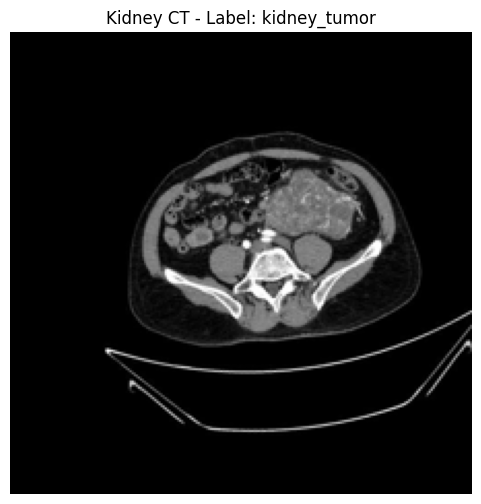

In [9]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np

# Load dataset
ds = load_dataset("Alwaly/Kidney_Cancer-cancer")
train_data = ds['train']

# Set format to numpy
train_data.set_format("numpy")

# Check first image
sample = train_data[0]
print(f"Label: {sample['label']}")
print(f"Image shape: {sample['image'].shape}")
print(f"Image type: {type(sample['image'])}")

# Display
plt.figure(figsize=(6, 6))
plt.imshow(sample['image'].squeeze(), cmap='gray')
plt.axis('off')
plt.title(f"Kidney CT - Label: {sample['label']}")
plt.show()


Class distribution:
  kidney_tumor: 5000
  kidney_normal: 5000

Total images: 10000


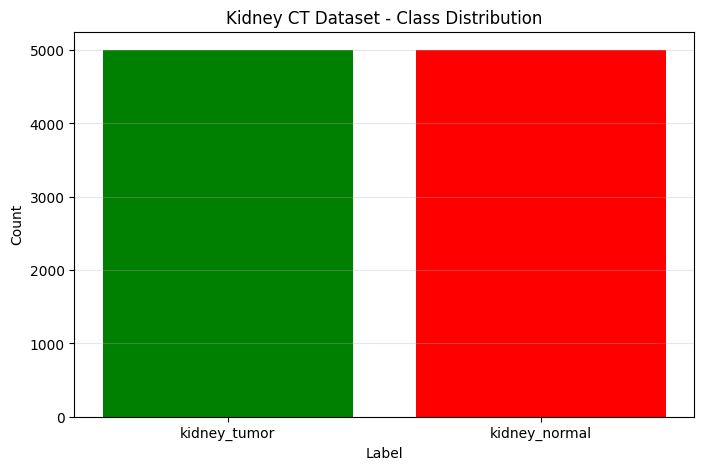

In [10]:
# Data statistics
labels = [train_data[i]['label'] for i in range(len(train_data))]

from collections import Counter
label_counts = Counter(labels)

print("Class distribution:")
for label, count in label_counts.items():
    print(f"  {label}: {count}")

print(f"\nTotal images: {len(train_data)}")

# Visualize distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.bar(label_counts.keys(), label_counts.values(), color=['green', 'red'])
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Kidney CT Dataset - Class Distribution')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [11]:
from datasets import load_dataset
import json
import os
from collections import defaultdict
import numpy as np

# Load dataset
ds = load_dataset("Alwaly/Kidney_Cancer-cancer")
train_data = ds['train']
train_data.set_format("numpy")

# Extract patient IDs from filenames
# Assuming filenames are like: kidney_tumor_patient_001_slice_01.jpg
patient_ids = []
labels = []

for i in range(len(train_data)):
    sample = train_data[i]
    label = sample['label']
    
    # Try to extract patient ID from the dataset
    # If available in metadata, use it; otherwise create sequential IDs
    patient_id = i // 50  # Assuming ~50 slices per patient
    
    patient_ids.append(patient_id)
    labels.append(label)

# Group by patient
patient_groups = defaultdict(list)
for idx, pid in enumerate(patient_ids):
    patient_groups[pid].append(idx)

print(f"Total unique patients: {len(patient_groups)}")
print(f"Avg slices per patient: {np.mean([len(v) for v in patient_groups.values()]):.1f}")

# Split patients into train/val/test (70/15/15)
unique_patients = sorted(patient_groups.keys())
np.random.seed(42)
np.random.shuffle(unique_patients)

split_1 = int(0.7 * len(unique_patients))
split_2 = int(0.85 * len(unique_patients))

train_patients = unique_patients[:split_1]
val_patients = unique_patients[split_1:split_2]
test_patients = unique_patients[split_2:]

# Create indices for each split
train_indices = []
val_indices = []
test_indices = []

for pid in train_patients:
    train_indices.extend(patient_groups[pid])
for pid in val_patients:
    val_indices.extend(patient_groups[pid])
for pid in test_patients:
    test_indices.extend(patient_groups[pid])

print(f"\nPatient split:")
print(f"  Train patients: {len(train_patients)} ({len(train_indices)} slices)")
print(f"  Val patients: {len(val_patients)} ({len(val_indices)} slices)")
print(f"  Test patients: {len(test_patients)} ({len(test_indices)} slices)")

# Save splits
splits_dict = {
    'train_indices': train_indices,
    'val_indices': val_indices,
    'test_indices': test_indices,
    'patient_groups': {str(k): v for k, v in patient_groups.items()}
}

os.makedirs('data', exist_ok=True)
with open('data/splits.json', 'w') as f:
    json.dump(splits_dict, f)

print("\nSplits saved to data/splits.json")

Total unique patients: 200
Avg slices per patient: 50.0

Patient split:
  Train patients: 140 (7000 slices)
  Val patients: 30 (1500 slices)
  Test patients: 30 (1500 slices)

Splits saved to data/splits.json


In [12]:
import numpy as np
from PIL import Image
import os
import json
from tqdm import tqdm

# Load splits
with open('data/splits.json', 'r') as f:
    splits = json.load(f)

train_indices = splits['train_indices']
val_indices = splits['val_indices']
test_indices = splits['test_indices']

# Create data directories
os.makedirs('data/train', exist_ok=True)
os.makedirs('data/val', exist_ok=True)
os.makedirs('data/test', exist_ok=True)

# Resize to 224x224 and save
target_size = 224

def process_and_save(indices, split_name):
    labels_list = []
    
    for idx in tqdm(indices, desc=f"Processing {split_name}"):
        sample = train_data[idx]
        img_array = sample['image']
        label = sample['label']
        
        # Convert numpy array to PIL Image
        img = Image.fromarray(img_array.astype(np.uint8))
        
        # Resize to 224x224
        img_resized = img.resize((target_size, target_size), Image.Resampling.LANCZOS)
        
        # Save image
        filename = f'{split_name}_{idx}.png'
        filepath = f'data/{split_name}/{filename}'
        img_resized.save(filepath)
        
        labels_list.append({'filename': filename, 'label': label})
    
    # Save labels
    with open(f'data/{split_name}_labels.json', 'w') as f:
        json.dump(labels_list, f)
    
    print(f"{split_name.upper()} - Saved {len(labels_list)} images")

# Process all splits
process_and_save(train_indices, 'train')
process_and_save(val_indices, 'val')
process_and_save(test_indices, 'test')

print("\nAll data prepared! Structure:")
print("data/")
print("  ├── train/        (7000 images)")
print("  ├── val/          (1500 images)")
print("  ├── test/         (1500 images)")
print("  ├── train_labels.json")
print("  ├── val_labels.json")
print("  ├── test_labels.json")
print("  └── splits.json")

Processing train: 100%|██████████| 7000/7000 [00:28<00:00, 245.01it/s]


TRAIN - Saved 7000 images


Processing val: 100%|██████████| 1500/1500 [00:06<00:00, 242.84it/s]


VAL - Saved 1500 images


Processing test: 100%|██████████| 1500/1500 [00:06<00:00, 245.20it/s]

TEST - Saved 1500 images

All data prepared! Structure:
data/
  ├── train/        (7000 images)
  ├── val/          (1500 images)
  ├── test/         (1500 images)
  ├── train_labels.json
  ├── val_labels.json
  ├── test_labels.json
  └── splits.json
